# Bài Thực Hành 2: Hồi Quy Tuyến Tính Đơn Biến

Trong bài thực hành này, ta sử dụng bộ dữ liệu `Social_media_impact_on_life.csv` (gồm một biến phụ thuộc và nhiều biến độc lập) để xây dựng và kiểm định mô hình hồi quy tuyến tính đơn biến. Cụ thể, ta chọn cặp biến có tương quan tuyến tính mạnh và sạch dữ liệu nhất:
- Biến độc lập $x$: `Daily_Usage_Hours` (số giờ sử dụng mạng xã hội mỗi ngày).
- Biến phụ thuộc $Y$: `Mental_Health_Index` (chỉ số sức khỏe tinh thần).

Mức ý nghĩa sử dụng cho toàn bộ các kiểm định là $\alpha = 0.05$ ($5\%$).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Doc du lieu tu file CSV
df = pd.read_csv('Social_media_impact_on_life.csv')

print(f"Kich thuoc dataset: {df.shape[0]} dong, {df.shape[1]} cot")
print("So gia tri thieu (missing) cua 2 bien dang xet:")
print(df[['Daily_Usage_Hours', 'Mental_Health_Index']].isnull().sum())

# Chuyen sang mang so thuc de tinh toan bang cong thuc so cap
x = df['Daily_Usage_Hours'].to_numpy(dtype=float)
y = df['Mental_Health_Index'].to_numpy(dtype=float)
n = len(x)

print(f"\nCo mau n = {n}")
display(df[['Daily_Usage_Hours', 'Mental_Health_Index']].head())

Kich thuoc dataset: 4500 dong, 16 cot
So gia tri thieu (missing) cua 2 bien dang xet:
Daily_Usage_Hours      0
Mental_Health_Index    0
dtype: int64

Co mau n = 4500


,Daily_Usage_Hours,Mental_Health_Index
0,7.5,73
1,4.6,90
2,10.9,70
3,6.0,82
4,3.3,84


---
## 1. Mô hình hồi quy tuyến tính & Giả thiết

Để mô tả mối quan hệ giữa thời gian sử dụng mạng xã hội ($x$) và chỉ số sức khỏe tinh thần ($Y$), ta xét mô hình hồi quy tuyến tính đơn biến lý thuyết:
$$Y = \beta_0 + \beta_1 x + \varepsilon$$

Mô hình được xây dựng dựa trên hệ giả thiết $(I)$ đối với sai số ngẫu nhiên $\varepsilon$: các sai số $\varepsilon_i$ độc lập với nhau, có kỳ vọng $E(\varepsilon) = 0$, phương sai không đổi $V(\varepsilon) = \sigma^2$, và tuân theo phân phối chuẩn $\varepsilon \sim N(0; \sigma^2)$. Từ đó suy ra $Y_i \sim N(\beta_0 + \beta_1 x_i;\; \sigma^2)$ độc lập.

Trước khi đi vào ước lượng tham số, ta vẽ biểu đồ phân tán để quan sát trực quan xem xu hướng giữa hai biến có dạng tuyến tính hay không.

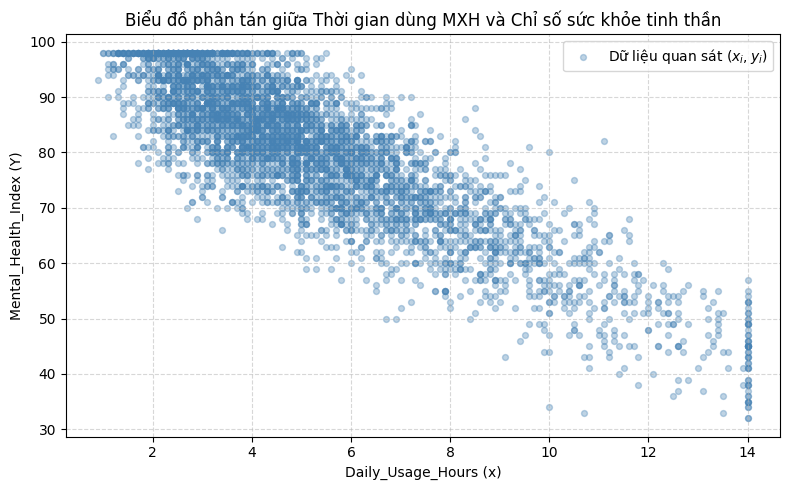

In [2]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.35, s=18, color='steelblue', label='Dữ liệu quan sát $(x_i, y_i)$')
plt.title('Biểu đồ phân tán giữa Thời gian dùng MXH và Chỉ số sức khỏe tinh thần')
plt.xlabel('Daily_Usage_Hours (x)')
plt.ylabel('Mental_Health_Index (Y)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

---
## 2. Ước lượng bình phương cực tiểu (OLS) & Mô hình thực nghiệm

Từ mẫu quan sát gồm $n$ cặp $(x_i, y_i)$, ta tính các tổng bình phương và tích chéo cơ bản:
$$S_{xx} = \sum_{i=1}^n (x_i - \bar{x})^2, \qquad S_{xy} = \sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y}), \qquad SS_T = \sum_{i=1}^n (y_i - \bar{y})^2$$

Theo phương pháp bình phương cực tiểu, cặp ước lượng $(\hat{\beta}_0, \hat{\beta}_1)$ được chọn sao cho tổng bình phương các phần dư $e_i = y_i - \hat{y}_i$ đạt giá trị nhỏ nhất, tức $\sum_{i=1}^n e_i^2 = SS_E \to \min$. Giải bài toán cực tiểu này cho ta:
$$\hat{\beta}_1 = \frac{S_{xy}}{S_{xx}}, \qquad \hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$
và thu được **mô hình hồi quy thực nghiệm**:
$$\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 x$$

Khi giả thiết $(I)$ được thỏa mãn, $\hat{\beta}_0$ và $\hat{\beta}_1$ đều là các ước lượng không chệch ($E(\hat{\beta}_0) = \beta_0,\; E(\hat{\beta}_1) = \beta_1$) với phương sai lần lượt là $V(\hat{\beta}_0) = \sigma^2 \left(\dfrac{1}{n} + \dfrac{\bar{x}^2}{S_{xx}}\right)$ và $V(\hat{\beta}_1) = \dfrac{\sigma^2}{S_{xx}}$.

Do phương sai sai số $\sigma^2$ chưa biết, ta dùng ước lượng không chệch cho $\sigma^2$ là $\hat{\sigma}^2 = s^2 = \dfrac{SS_E}{n - 2}$, trong đó $SS_E$ có thể tính trực tiếp từ $\sum e_i^2$ hoặc bằng công thức thuận tiện $SS_E = SS_T - \hat{\beta}_1 S_{xy}$. Căn bậc hai của $\hat{\sigma}^2$ chính là **sai số chuẩn của mô hình**:
$$s = \sqrt{\frac{SS_E}{n - 2}}$$

In [3]:
# Tinh trung binh mau bang ham so cap
x_bar = sum(x) / n
y_bar = sum(y) / n

# Tinh S_xx, S_xy, SS_T theo dinh nghia
S_xx = sum((x - x_bar) ** 2)
S_xy = sum((x - x_bar) * (y - y_bar))
SS_T = sum((y - y_bar) ** 2)

# Uoc luong binh phuong cuc tieu
beta_1_hat = S_xy / S_xx
beta_0_hat = y_bar - beta_1_hat * x_bar

# Gia tri du bao va phan du
y_hat = beta_0_hat + beta_1_hat * x
e = y - y_hat

# Tinh SS_E theo 2 cach de doi chieu
SS_E_cach1 = sum(e ** 2)
SS_E_cach2 = SS_T - beta_1_hat * S_xy
SS_E = SS_E_cach1

# Uoc luong phuong sai sai so va sai so chuan cua mo hinh
s_squared = SS_E / (n - 2)
s = s_squared ** 0.5

print(f"x_bar = {x_bar:.4f}, y_bar = {y_bar:.4f}")
print(f"S_xx  = {S_xx:.4f}")
print(f"S_xy  = {S_xy:.4f}")
print(f"SS_T  = {SS_T:.4f}")
print("-" * 50)
print(f"beta_1_hat = {beta_1_hat:.4f}")
print(f"beta_0_hat = {beta_0_hat:.4f}")
print(f"Mo hinh hoi quy thuc nghiem: y_hat = {beta_0_hat:.4f} + ({beta_1_hat:.4f}) * x")
print("-" * 50)
print(f"SS_E (Cach 1: sum(e_i^2))          = {SS_E_cach1:.4f}")
print(f"SS_E (Cach 2: SS_T - beta_1*S_xy)  = {SS_E_cach2:.4f}")
print(f"Uoc luong sigma^2 = SS_E / (n - 2) = {s_squared:.4f}")
print(f"Sai so chuan cua mo hinh (s)       = {s:.4f}")

x_bar = 5.2959, y_bar = 79.8731
S_xx  = 30518.5356
S_xy  = -128231.3221
SS_T  = 745900.5464
--------------------------------------------------
beta_1_hat = -4.2018
beta_0_hat = 102.1253
Mo hinh hoi quy thuc nghiem: y_hat = 102.1253 + (-4.2018) * x
--------------------------------------------------
SS_E (Cach 1: sum(e_i^2))          = 207104.3150
SS_E (Cach 2: SS_T - beta_1*S_xy)  = 207104.3150
Uoc luong sigma^2 = SS_E / (n - 2) = 46.0436
Sai so chuan cua mo hinh (s)       = 6.7855


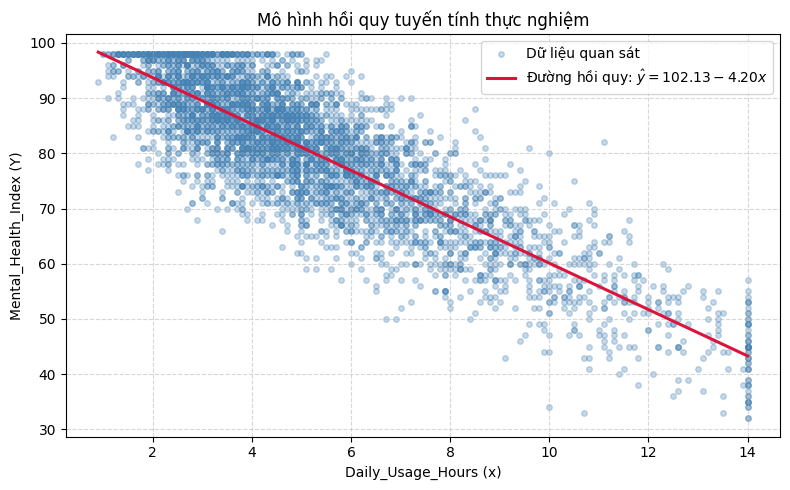

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(x, y, alpha=0.3, s=16, color='steelblue', label='Dữ liệu quan sát')
x_line = np.array([min(x), max(x)])
y_line = beta_0_hat + beta_1_hat * x_line
plt.plot(
    x_line, y_line, color='crimson', linewidth=2.2,
    label=rf'Đường hồi quy: $\hat{{y}} = {beta_0_hat:.2f} {beta_1_hat:.2f}x$'
)
plt.title('Mô hình hồi quy tuyến tính thực nghiệm')
plt.xlabel('Daily_Usage_Hours (x)')
plt.ylabel('Mental_Health_Index (Y)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

---
## 3. Bài toán dự đoán

Khi đã có phương trình hồi quy thực nghiệm $\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 x$, với một giá trị $x_0$ nằm trong miền quan sát của biến độc lập, ta có thể dự đoán giá trị trung bình của biến phụ thuộc bằng cách thay trực tiếp vào mô hình:
$$\hat{y}_0 = \hat{\beta}_0 + \hat{\beta}_1 x_0$$

Dưới đây ta thử dự đoán chỉ số sức khỏe tinh thần tại một số mức thời gian dùng mạng xã hội (2, 5 và 8 giờ/ngày), đồng thời đối chiếu giá trị dự đoán với giá trị thực tế qua phần dư $e_i = y_i - \hat{y}_i$ trên 5 quan sát đầu tiên.

In [5]:
# Du doan chi so suc khoe tinh than voi cac muc su dung MXH x_0 khac nhau
x_0_list = [2.0, 5.0, 8.0]
print("Ket qua du doan:")
for x_0 in x_0_list:
    y_0_hat = beta_0_hat + beta_1_hat * x_0
    print(f"  - Voi x_0 = {x_0:.1f} gio/ngay => y_0_hat = {y_0_hat:.4f}")

# Doi chieu gia tri thuc te, du doan va phan du cua 5 quan sat dau tien
df_check = pd.DataFrame({
    'x_i': x[:5],
    'y_i (Thuc te)': y[:5],
    'y_hat_i (Du doan)': np.round(y_hat[:5], 4),
    'e_i = y_i - y_hat_i': np.round(e[:5], 4)
})
display(df_check)

Ket qua du doan:
  - Voi x_0 = 2.0 gio/ngay => y_0_hat = 93.7218
  - Voi x_0 = 5.0 gio/ngay => y_0_hat = 81.1165
  - Voi x_0 = 8.0 gio/ngay => y_0_hat = 68.5113


,x_i,y_i (Thuc te),y_hat_i (Du doan),e_i = y_i - y_hat_i
0,7.5,73.0,70.6122,2.3878
1,4.6,90.0,82.7973,7.2027
2,10.9,70.0,56.3262,13.6738
3,6.0,82.0,76.9148,5.0852
4,3.3,84.0,88.2595,-4.2595


---
## 4. Kiểm tra hai biến có liên hệ tuyến tính (mức ý nghĩa $\alpha = 0.05$)

Câu hỏi đặt ra là: biến độc lập $x$ có thực sự hữu ích trong việc giải thích và dự đoán $Y$ hay không? Để trả lời, ta kiểm định xem hệ số góc $\beta_1$ có khác $0$ một cách có ý nghĩa thống kê hay không bằng hai cách tiếp cận tương đương.

### Cách 1: Kiểm định Student về hệ số góc $\beta_1$

Ta xét cặp giả thuyết $H_0: \beta_1 = 0$ (hai biến không có liên hệ tuyến tính) đối đầu với đối thuyết $H_1: \beta_1 \neq 0$ (hai biến có liên hệ tuyến tính).

Nếu $H_0$ đúng và giả thiết $(I)$ được thỏa mãn, thống kê kiểm định dưới đây tuân theo phân phối Student với $(n - 2)$ bậc tự do:
$$T = \frac{\hat{\beta}_1 - 0}{s / \sqrt{S_{xx}}} \stackrel{H_0\text{ đúng}}{\sim} t(n - 2), \quad \text{với } s = \sqrt{\frac{SS_E}{n - 2}}$$

Với mức ý nghĩa $\alpha = 0.05$, miền bác bỏ hai phía là:
$$W_\alpha = \left(-\infty;\; -t_{\alpha/2}^{(n-2)}\right) \cup \left(t_{\alpha/2}^{(n-2)};\; +\infty\right)$$

Ta tính giá trị quan sát $t_{qs} = \dfrac{\hat{\beta}_1}{s / \sqrt{S_{xx}}}$ và kiểm tra xem $t_{qs}$ có rơi vào $W_\alpha$ hay không để đưa ra kết luận.

In [6]:
alpha = 0.05
df_err = n - 2

# Tinh sai so chuan cua beta_1_hat va gia tri quan sat t_qs
se_beta_1 = s / (S_xx ** 0.5)
t_qs = (beta_1_hat - 0) / se_beta_1

# Tim gia tri toi han t_{alpha/2}^{(n-2)}
t_crit = stats.t.ppf(1 - alpha / 2, df=df_err)

print(f"Bac tu do: n - 2 = {df_err}")
print(f"Mien bac bo W_alpha = (-inf; {-t_crit:.4f}) U ({t_crit:.4f}; +inf)")
print(f"Gia tri quan sat t_qs = {t_qs:.4f}")

if abs(t_qs) > t_crit:
    print("=> t_qs thuoc W_alpha => Bac bo H_0.")
    print("Ket luan: Bien x (Daily_Usage_Hours) va bien y (Mental_Health_Index) CO lien he tuyen tinh (x co y nghia trong viec du doan y).")
else:
    print("=> t_qs khong thuoc W_alpha => Chua co co so bac bo H_0.")

Bac tu do: n - 2 = 4498
Mien bac bo W_alpha = (-inf; -1.9605) U (1.9605; +inf)
Gia tri quan sat t_qs = -108.1751
=> t_qs thuoc W_alpha => Bac bo H_0.
Ket luan: Bien x (Daily_Usage_Hours) va bien y (Mental_Health_Index) CO lien he tuyen tinh (x co y nghia trong viec du doan y).


### Cách 2: Kiểm định Fisher bằng phân tích phương sai (ANOVA)

Thay vì kiểm định trực tiếp $\beta_1$, ta có thể đánh giá ý nghĩa của mô hình hồi quy thông qua việc phân tách tổng biến thiên $SS_T$ thành hai phần: biến thiên giải thích được bởi hồi quy ($SS_R$) và biến thiên do sai số ngẫu nhiên ($SS_E$):
$$SS_T = SS_E + SS_R, \quad \text{với } SS_R = \sum_{i=1}^n (\hat{y}_i - \bar{y})^2$$
trong đó $SS_T$, $SS_R$ và $SS_E$ lần lượt có bậc tự do là $(n - 1)$, $1$ và $(n - 2)$.

Vẫn với cặp giả thuyết $H_0: \beta_1 = 0$ và $H_1: \beta_1 \neq 0$, khi $H_0$ đúng và giả thiết $(I)$ thỏa mãn, tỉ số giữa bình phương trung bình hồi quy ($MS_R$) và bình phương trung bình sai số ($MS_E$) tuân theo phân phối Fisher:
$$F = \frac{SS_R / 1}{SS_E / (n - 2)} = \frac{MS_R}{MS_E} \stackrel{H_0\text{ đúng},\; GT(I)}{\sim} F(1;\; n - 2)$$

Miền bác bỏ tương ứng ở mức ý nghĩa $\alpha = 0.05$ nằm ở đuôi phải:
$$W_\alpha = \left(F_{(\alpha;\; 1;\; n-2)};\; +\infty\right)$$

Cuối cùng, ta tính giá trị quan sát $F_{qs} = \dfrac{MS_R}{MS_E}$, tổng hợp kết quả vào bảng ANOVA và đối chiếu với $W_\alpha$ để kết luận.

In [7]:
# Tinh SS_R theo dinh nghia so cap
SS_R = sum((y_hat - y_bar) ** 2)

# Tinh MS_R, MS_E va F_qs
df_reg = 1
MS_R = SS_R / df_reg
MS_E = SS_E / df_err
F_qs = MS_R / MS_E

# Tim gia tri toi han F_{(alpha; 1; n-2)}
F_crit = stats.f.ppf(1 - alpha, dfn=df_reg, dfd=df_err)

# Lap bang ANOVA chuan trinh bay
anova_table = pd.DataFrame({
    'Nguồn': ['Hồi quy', 'Sai số', 'Tổng'],
    'Tổng bình phương': [round(SS_R, 4), round(SS_E, 4), round(SS_T, 4)],
    'Bậc tự do': [df_reg, df_err, n - 1],
    'Bình phương trung bình': [round(MS_R, 4), round(MS_E, 4), ''],
    'Giá trị quan sát (qs)': [round(F_qs, 4), '', '']
})
display(anova_table)

print(f"Mien bac bo W_alpha = ({F_crit:.4f}; +inf)")
print(f"Gia tri quan sat F_qs = {F_qs:.4f}")

if F_qs > F_crit:
    print("=> F_qs thuoc W_alpha => Bac bo H_0.")
    print("Ket luan: Mo hinh hoi quy co y nghia thong ke (hai bien CO lien he tuyen tinh).")
else:
    print("=> F_qs khong thuoc W_alpha => Chua co co so bac bo H_0.")

# Kiem tra cheo logic toan hoc
print("\n--- KIEM TRA CHEO LOGIC ---")
print(f"SS_R + SS_E = {SS_R + SS_E:.4f} vs SS_T = {SS_T:.4f}")
print(f"t_qs^2      = {t_qs**2:.4f} vs F_qs = {F_qs:.4f}")
print(f"t_crit^2    = {t_crit**2:.4f} vs F_crit = {F_crit:.4f}")

# Doi chieu voi scipy.stats.linregress
res = stats.linregress(x, y)
print(f"scipy linregress: slope={res.slope:.4f}, intercept={res.intercept:.4f}, r={res.rvalue:.4f}, p={res.pvalue:.2e}")

,Nguồn,Tổng bình phương,Bậc tự do,Bình phương trung bình,Giá trị quan sát (qs)
0,Hồi quy,538796.2314,1,538796.2314,11701.8588
1,Sai số,207104.3150,4498,46.0436,
2,Tổng,745900.5464,4499,,


Mien bac bo W_alpha = (3.8435; +inf)
Gia tri quan sat F_qs = 11701.8588
=> F_qs thuoc W_alpha => Bac bo H_0.
Ket luan: Mo hinh hoi quy co y nghia thong ke (hai bien CO lien he tuyen tinh).

--- KIEM TRA CHEO LOGIC ---
SS_R + SS_E = 745900.5464 vs SS_T = 745900.5464
t_qs^2      = 11701.8588 vs F_qs = 11701.8588
t_crit^2    = 3.8435 vs F_crit = 3.8435
scipy linregress: slope=-4.2018, intercept=102.1253, r=-0.8499, p=0.00e+00
